### Normalverteilung: Glockenkurve, Wahrscheinlichkeiten, Näherung, Dichtefunktion - Übungen

In diesem Notebook geht es um die **Normalverteilung**: Körpergrößen, Messfehler, Füllmengen oder Gewichte sind oft annähernd
normalverteilt. Ihre Wahrscheinlichkeiten werden durch die Fläche unter einer **Glockenkurve** beschrieben.

Du berechnest Wahrscheinlichkeiten mit `sympy.stats`, untersuchst, wie die Glockenkurve von Erwartungswert μ und Standardabweichung σ abhängt,
löst Umkehraufgaben (Welcher Wert wird nur von 10 % überschritten?) und nähert die Binomialverteilung durch die Normalverteilung an.
Im **Leistungsfach** untersuchst du die Dichtefunktion mit Mitteln der Analysis.

Vorausgesetzt werden die Notebooks *Wahrscheinlichkeit* und *Integrale*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und `sympy.stats`, schaltet die Formel-Ausgabe ein,
lädt matplotlib und legt die Variable `x` an. **Achtung:** `sympy.stats` verwendet `E` für den Erwartungswert und `P` für Wahrscheinlichkeiten.

In [ ]:
from sympy import *
from sympy.stats import *
init_printing()
import matplotlib.pyplot as plt
x = symbols('x', real=True)

## 1. Die Glockenkurve

#### Normalverteilte Zufallsgrößen

Eine **stetige** Zufallsgröße kann jeden Wert in einem Intervall annehmen (z. B. eine Körpergröße), eine **diskrete** nur einzelne Werte
(z. B. eine Anzahl). Bei einer **normalverteilten** Zufallsgröße X mit Erwartungswert μ und Standardabweichung σ liegen die Werte
glockenförmig um μ verteilt.

- `X = Normal('X', mu, sigma)` legt sie an (zweiter Wert: Erwartungswert, dritter: **Standardabweichung**).
- `density(X)(x)` ist der Term der **Glockenkurve** (Dichtefunktion).
- Je größer σ, desto breiter und flacher die Kurve. Die Fläche unter der Kurve ist immer 1.

Beispiel: Die Körpergröße erwachsener Männer ist annähernd normalverteilt mit μ = 178 cm und σ = 7 cm.

In [ ]:
X = Normal('X', 178, 7)
f = density(X)(x)
display(f)
display(E(X), std(X))
plot(f, (x, 150, 206));

#### Aufgabe 1.1

Lege X normalverteilt mit μ = 100, σ = 15 an (z. B. IQ-Werte) und gib den Term der Glockenkurve aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{\sqrt{2} e^{- \frac{\left(x - 100\right)^{2}}{450}}}{30 \sqrt{\pi}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 100, 15)
density(X)(x)
```

</details>

#### Aufgabe 1.2

Zeichne die Glockenkurven für μ = 0 und σ = 1, σ = 2, σ = 0,5 in ein Diagramm (−6 ≤ x ≤ 6, mit Legende).

**Erwartete Ausgabe:**



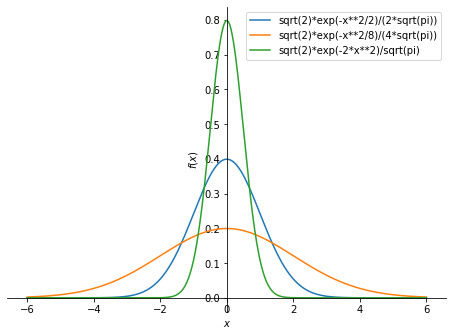

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(*[density(Normal('X', 0, s))(x) for s in [1, 2, Rational(1, 2)]], (x, -6, 6), legend=True);
```

</details>

#### Aufgabe 1.3

Zeichne die Glockenkurven für σ = 1 und μ = −2, 0, 3 in ein Diagramm (−6 ≤ x ≤ 7, mit Legende).

**Erwartete Ausgabe:**



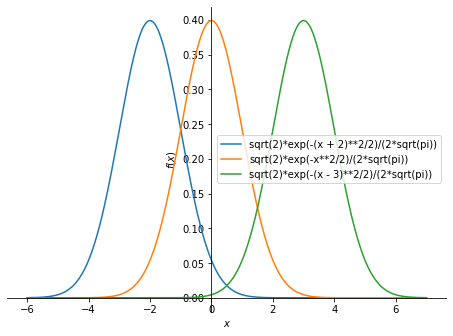

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(*[density(Normal('X', m, 1))(x) for m in [-2, 0, 3]], (x, -6, 7), legend=True);
```

</details>

#### Aufgabe 1.4

Gib die Höhe des Hochpunkts der Glockenkurve für μ = 0 und σ = 1, 2 und 0,5 genau aus (Wert an der Stelle μ).

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{\sqrt{2}}{2 \sqrt{\pi}}, \  \frac{\sqrt{2}}{4 \sqrt{\pi}}, \  \frac{\sqrt{2}}{\sqrt{\pi}}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[density(Normal('X', 0, s))(0) for s in [1, 2, Rational(1, 2)]]
```

</details>

#### Aufgabe 1.5

Zeige mit einer Rechnung, dass die Glockenkurve für μ = 178, σ = 7 symmetrisch zu x = 178 ist: `simplify(f(178 + x) − f(178 − x))` muss 0 sein.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = density(Normal('X', 178, 7))
simplify(f(178 + x) - f(178 - x))
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Normal('X', 5, 2)
display(E(X))
display(std(X))
variance(X)
```

In [ ]:
X = Normal('X', 5, 2)
display(E(X))
display(std(X))
variance(X)

## 2. Wahrscheinlichkeiten berechnen

#### Flächen unter der Glockenkurve

Bei stetigen Zufallsgrößen haben **Intervalle** eine Wahrscheinlichkeit, einzelne Werte nicht: P(X = a) = 0.
Deshalb ist P(X ≤ a) = P(X < a).

- P(X ≤ a): `P(X <= a)`
- P(a ≤ X ≤ b): `P((X >= a) & (X <= b))`
- P(X ≥ a): `P(X >= a)` = 1 − P(X ≤ a)

Die Ergebnisse enthalten die Fehlerfunktion `erf`; mit `N()` bekommst du Zahlen.

Zum Zeichnen mit matplotlib (z. B. Flächen färben mit `plt.fill_between`) braucht man eine Python-Funktion statt eines sympy-Terms:
`fl = lambdify(x, term)` erzeugt sie, `fl(3.5)` berechnet dann einen Wert.

In [ ]:
X = Normal('X', 178, 7)
display(P(X <= 185))
display(N(P(X <= 185), 4))
display(N(P((X >= 170) & (X <= 185)), 4))
display(N(P(X >= 190), 4))
P(Eq(X, 180))

#### Aufgabe 2.1

Wie groß ist die Wahrscheinlichkeit, dass ein Mann (μ = 178, σ = 7) kleiner als 170 cm ist? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 0.1265$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(P(X <= 170), 4)
```

</details>

#### Aufgabe 2.2

Wie groß ist die Wahrscheinlichkeit, dass ein Mann zwischen 175 und 185 cm groß ist? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 0.5072$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(P((X >= 175) & (X <= 185)), 4)
```

</details>

#### Aufgabe 2.3

Wie viel Prozent der Männer sind größer als 2 m? (3 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 0.0836$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(100 * P(X >= 200), 3)
```

</details>

#### Aufgabe 2.4

Eine Maschine füllt Zuckerpakete mit μ = 1000 g und σ = 8 g. Ein Paket mit weniger als 985 g ist Ausschuss. Wie viel Prozent Ausschuss gibt es? (3 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 3.04$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 1000, 8)
N(100 * P(X <= 985), 3)
```

</details>

#### Aufgabe 2.5

Wie groß ist für die Maschine aus der vorigen Aufgabe die Wahrscheinlichkeit, dass ein Paket um höchstens 10 g von 1000 g abweicht? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 0.7887$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 1000, 8)
N(P((X >= 990) & (X <= 1010)), 4)
```

</details>

#### Aufgabe 2.6

Ein Bus braucht für eine Strecke im Mittel 24 Minuten mit σ = 3 Minuten. Mit welcher Wahrscheinlichkeit braucht er länger als 30 Minuten?
Wie viele von 200 Fahrten dauern also etwa länger als 30 Minuten (gerundet)?

**Erwartete Ausgabe:**

$\displaystyle 0.02275$

$\displaystyle 5$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 24, 3)
p = P(X >= 30)
display(N(p, 4))
round(N(200 * p))
```

</details>

#### Aufgabe 2.7

Zeichne die Glockenkurve für μ = 178, σ = 7 und markiere die Fläche für 175 ≤ X ≤ 185 mit `plt.fill_between`. Verwende dafür Listen von x-Werten und Funktionswerten
(`lambdify` macht aus dem sympy-Term eine Python-Funktion: `fl = lambdify(x, f)`).

**Erwartete Ausgabe:**



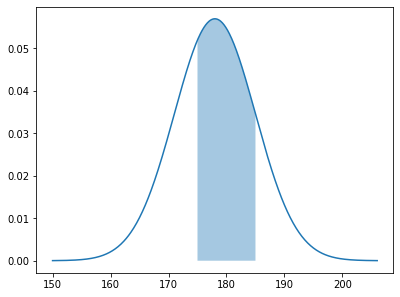

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = density(Normal('X', 178, 7))(x)
fl = lambdify(x, f)
xs = [150 + i / 10 for i in range(561)]
plt.plot(xs, [fl(w) for w in xs])
xf = [175 + i / 10 for i in range(101)]
plt.fill_between(xf, [fl(w) for w in xf], alpha=0.4)
plt.show()
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Normal('X', 0, 1)
display(P(X <= 0))
display(P(X >= 0))
P(Eq(X, 0))
```

In [ ]:
X = Normal('X', 0, 1)
display(P(X <= 0))
display(P(X >= 0))
P(Eq(X, 0))

## 3. Die Sigma-Regeln

#### Wie viel liegt in μ ± kσ?

Für **jede** Normalverteilung gilt (unabhängig von μ und σ):

| Intervall | Wahrscheinlichkeit |
|---|---|
| [μ − σ, μ + σ] | ≈ 68,3 % |
| [μ − 2σ, μ + 2σ] | ≈ 95,4 % |
| [μ − 3σ, μ + 3σ] | ≈ 99,7 % |

Mit der **Standardnormalverteilung** (μ = 0, σ = 1) lässt sich das nachrechnen.

In [ ]:
Z = Normal('Z', 0, 1)
[N(P((Z >= -k) & (Z <= k)), 4) for k in [1, 2, 3]]

#### Aufgabe 3.1

Prüfe die 1-σ-Regel für μ = 178, σ = 7: Berechne P(171 ≤ X ≤ 185) mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.6827$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(P((X >= 171) & (X <= 185)), 4)
```

</details>

#### Aufgabe 3.2

Berechne für die Standardnormalverteilung P(−1,96 ≤ Z ≤ 1,96) und P(−2,58 ≤ Z ≤ 2,58) mit 4 Ziffern (Zahlen als `Rational`).

**Erwartete Ausgabe:**

$\displaystyle 0.95$

$\displaystyle 0.9901$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Z = Normal('Z', 0, 1)
display(N(P((Z >= -Rational(196, 100)) & (Z <= Rational(196, 100))), 4))
N(P((Z >= -Rational(258, 100)) & (Z <= Rational(258, 100))), 4)
```

</details>

#### Aufgabe 3.3

Der IQ ist normalverteilt mit μ = 100 und σ = 15. In welchem Intervall liegen etwa 95,4 % aller Werte? Gib die Grenzen μ ± 2σ aus.

**Erwartete Ausgabe:**

$\displaystyle \left( 70, \  130\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
mu, sigma = 100, 15
(mu - 2 * sigma, mu + 2 * sigma)
```

</details>

#### Aufgabe 3.4

Bestimme für die Standardnormalverteilung den Wert k mit P(−k ≤ Z ≤ k) = 0,9. `P` kann nicht mit einem Symbol k als Grenze rechnen; verwende deshalb
die Verteilungsfunktion F = `cdf(Z)` (F(k) = P(Z ≤ k)): Wegen der Symmetrie ist P(−k ≤ Z ≤ k) = 2·F(k) − 1. Löse mit `nsolve` (Startwert 1,5, 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 1.645$

In [ ]:
k = symbols('k', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k', positive=True)
F = cdf(Normal('Z', 0, 1))
N(nsolve(2 * F(k) - 1 - Rational(9, 10), k, 1.5), 4)
```

</details>

## 4. Umkehraufgaben

#### Grenzen und Parameter bestimmen

- **Grenze gesucht:** Welche Körpergröße wird von 90 % der Männer nicht überschritten? Gesucht ist a mit P(X ≤ a) = 0,9.
  `quantile(X)(Rational(9, 10))` gibt a direkt aus (das **Quantil**).
- **Parameter gesucht:** Wie groß darf σ höchstens sein, damit ...? Man stellt die Gleichung mit einem Symbol auf und löst sie mit `nsolve`.

In [ ]:
X = Normal('X', 178, 7)
a = quantile(X)(Rational(9, 10))
display(N(a, 5))
display(N(P(X <= a), 4))
s = symbols('s', positive=True)
Y = Normal('Y', 1000, s)
N(nsolve(P(Y <= 985) - Rational(1, 100), s, 5), 4)

#### Aufgabe 4.1

Welche Körpergröße wird von 95 % der Männer (μ = 178, σ = 7) nicht überschritten? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 189.5$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(quantile(X)(Rational(95, 100)), 4)
```

</details>

#### Aufgabe 4.2

Unterhalb welcher Größe liegen die kleinsten 10 % der Männer? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 169.0$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
N(quantile(X)(Rational(1, 10)), 4)
```

</details>

#### Aufgabe 4.3

Bestimme das Intervall [μ − c, μ + c] für μ = 178, σ = 7, in dem die mittleren 80 % der Körpergrößen liegen (Grenzen mit den Quantilen 0,1 und 0,9, 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \left( 169.0, \  187.0\right)$

In [ ]:
X = Normal('X', 178, 7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
(N(quantile(X)(Rational(1, 10)), 4), N(quantile(X)(Rational(9, 10)), 4))
```

</details>

#### Aufgabe 4.4

Ein IQ-Test: Die besten 2 % sollen eine Auszeichnung bekommen. Ab welchem Wert gibt es sie (μ = 100, σ = 15, 4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 130.8$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(quantile(Normal('X', 100, 15))(Rational(98, 100)), 4)
```

</details>

#### Aufgabe 4.5

Auf welchen Mittelwert μ muss die Zuckermaschine (σ = 8 g) eingestellt werden, damit nur 1 % der Pakete unter 985 g wiegen? (`nsolve`, Startwert 1000, 5 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 1003.6$

In [ ]:
m = symbols('m', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = symbols('m', real=True)
N(nsolve(P(Normal('X', m, 8) <= 985) - Rational(1, 100), m, 1000), 5)
```

</details>

#### Aufgabe 4.6

Ein Lehrer gibt eine Klausur. Die Punkte sind normalverteilt mit μ = 30. Wie groß ist σ, wenn 16 % der Schüler mehr als 40 Punkte haben? (`nsolve`, Startwert 8, 4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 10.06$

In [ ]:
s = symbols('s', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s = symbols('s', positive=True)
N(nsolve(P(Normal('X', 30, s) >= 40) - Rational(16, 100), s, 8), 4)
```

</details>

## 5. Näherung der Binomialverteilung

#### Binomialverteilung ≈ Normalverteilung

Für großes n sieht das Histogramm der Binomialverteilung wie eine Glockenkurve aus. Man nähert sie durch die Normalverteilung mit
μ = n·p und σ = √(n·p·(1 − p)) an. Faustregel: Die Näherung ist brauchbar, wenn σ > 3.

Weil die Binomialverteilung nur ganze Zahlen kennt, rechnet man bei P(X ≤ k) mit der Grenze k + 0,5 (**Stetigkeitskorrektur**).

In [ ]:
n, p = 100, Rational(1, 2)
B = Binomial('B', n, p)
mu, sigma = n * p, sqrt(n * p * (1 - p))
X = Normal('X', mu, sigma)
display(mu, sigma)
display(N(P(B <= 45), 4), N(P(X <= Rational(91, 2)), 4))
d = density(B).dict
werte = list(range(30, 71))
plt.bar(werte, [N(d[k]) for k in werte])
fl = lambdify(x, density(X)(x))
plt.plot(werte, [fl(k) for k in werte], 'r')
plt.show()

#### Aufgabe 5.1

Ein Würfel wird 600-mal geworfen, B ist die Anzahl der Sechsen. Gib μ und σ (4 Ziffern) aus und prüfe die Faustregel σ > 3.

**Erwartete Ausgabe:**

$\displaystyle 100$

$\displaystyle 9.129$

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 600, Rational(1, 6)
sigma = sqrt(n * p * (1 - p))
display(n * p, N(sigma, 4))
sigma > 3
```

</details>

#### Aufgabe 5.2

Berechne für den Würfel aus der vorigen Aufgabe P(B ≤ 90) exakt mit der Binomialverteilung und genähert mit der Normalverteilung (mit Stetigkeitskorrektur), beide mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.1487$

$\displaystyle 0.149$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 600, Rational(1, 6)
B = Binomial('B', n, p)
X = Normal('X', n * p, sqrt(n * p * (1 - p)))
display(N(P(B <= 90), 4))
N(P(X <= Rational(181, 2)), 4)
```

</details>

#### Aufgabe 5.3

Berechne P(90 ≤ B ≤ 110) für den Würfel exakt (über `cdf(B)`) und genähert (Grenzen 89,5 und 110,5), beide mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.7501$

$\displaystyle 0.7499$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 600, Rational(1, 6)
F = cdf(Binomial('B', n, p))
X = Normal('X', n * p, sqrt(n * p * (1 - p)))
display(N(F[110] - F[89], 4))
N(P((X >= Rational(179, 2)) & (X <= Rational(221, 2))), 4)
```

</details>

#### Aufgabe 5.4

Für n = 20, p = 0,1 ist σ < 3. Vergleiche P(B ≤ 1) exakt und genähert (Grenze 1,5), beide mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.3917$

$\displaystyle 0.3547$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 20, Rational(1, 10)
B = Binomial('B', n, p)
X = Normal('X', n * p, sqrt(n * p * (1 - p)))
display(N(P(B <= 1), 4))
N(P(X <= Rational(3, 2)), 4)
```

</details>

#### Aufgabe 5.5

Zeichne wie im Beispiel das Histogramm der Binomialverteilung für n = 50, p = 0,3 (0 ≤ k ≤ 30) zusammen mit der Glockenkurve der Näherung.

**Erwartete Ausgabe:**



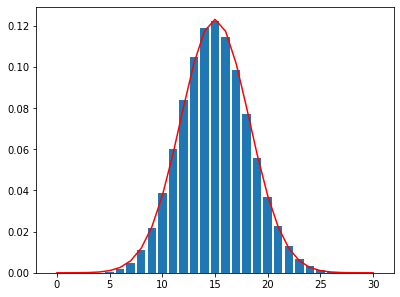

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 50, Rational(3, 10)
d = density(Binomial('B', n, p)).dict
werte = list(range(31))
plt.bar(werte, [N(d[k]) for k in werte])
fl = lambdify(x, density(Normal('X', n * p, sqrt(n * p * (1 - p))))(x))
plt.plot(werte, [fl(k) for k in werte], 'r')
plt.show()
```

</details>

## 6. Dichtefunktion und Integral (Leistungsfach)

#### Wahrscheinlichkeit = Integral der Dichte

Eine **Dichtefunktion** f ist nie negativ und hat die Gesamtfläche ∫₋∞^∞ f(x) dx = 1. Für eine stetige Zufallsgröße mit Dichte f gilt

P(a ≤ X ≤ b) = ∫ₐᵇ f(x) dx, E(X) = μ = ∫₋∞^∞ x · f(x) dx, Var(X) = σ² = ∫₋∞^∞ (x − μ)² · f(x) dx.

Die **Verteilungsfunktion** F(x) = P(X ≤ x) ist eine Integralfunktion der Dichte: F' = f. In sympy: `cdf(X)(x)`.

Die Glockenkurve von Normal(μ, σ) ist f(x) = 1/(σ√(2π)) · e^(−(x − μ)²/(2σ²)).

In [ ]:
mu, sigma = symbols('mu sigma', positive=True)
f = exp(-(x - mu)**2 / (2 * sigma**2)) / (sigma * sqrt(2 * pi))
display(f)
display(simplify(f - density(Normal('X', mu, sigma))(x)))
display(simplify(integrate(f, (x, -oo, oo))))
display(solve(diff(f, x), x), solve(diff(f, x, 2), x))
Fx = cdf(Normal('X', mu, sigma))(x)
display(Fx)
simplify(diff(Fx, x) - f)

#### Aufgabe 6.1

Berechne für μ = 178, σ = 7 die Wahrscheinlichkeit P(175 ≤ X ≤ 185) als Integral der Dichte (4 Ziffern) und vergleiche mit `P(...)`.

**Erwartete Ausgabe:**

$\displaystyle 0.5072$

$\displaystyle 0.5072$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 178, 7)
f = density(X)(x)
display(N(integrate(f, (x, 175, 185)), 4))
N(P((X >= 175) & (X <= 185)), 4)
```

</details>

#### Aufgabe 6.2

Berechne den Erwartungswert der Normalverteilung mit μ = 3, σ = 2 als Integral ∫ x · f(x) dx.

**Erwartete Ausgabe:**

$\displaystyle 3$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = density(Normal('X', 3, 2))(x)
simplify(integrate(x * f, (x, -oo, oo)))
```

</details>

#### Aufgabe 6.3

Berechne die Varianz der Normalverteilung mit μ = 3, σ = 2 als Integral ∫ (x − 3)² · f(x) dx.

**Erwartete Ausgabe:**

$\displaystyle 4$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = density(Normal('X', 3, 2))(x)
simplify(integrate((x - 3)**2 * f, (x, -oo, oo)))
```

</details>

#### Aufgabe 6.4

Bestimme für die Glockenkurve mit μ = 178, σ = 7 den Hochpunkt und die Wendestellen.

**Erwartete Ausgabe:**

$\displaystyle \left[ 178\right]$

$\displaystyle \left[ 171, \  185\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = density(Normal('X', 178, 7))(x)
display(solve(diff(f, x), x))
solve(diff(f, x, 2), x)
```

</details>

#### Aufgabe 6.5

Prüfe, ob f(x) = 3/4 · (1 − x²) für −1 ≤ x ≤ 1 (sonst 0) eine Dichtefunktion ist: Gib das Integral über [−1, 1] aus und den kleinsten Wert von f auf [−1, 1].

**Erwartete Ausgabe:**

$\displaystyle 1$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Rational(3, 4) * (1 - x**2)
display(integrate(f, (x, -1, 1)))
minimum(f, x, Interval(-1, 1))
```

</details>

#### Aufgabe 6.6

Berechne für die Dichte aus der vorigen Aufgabe P(0 ≤ X ≤ 0,5), den Erwartungswert und die Standardabweichung (alle genau).

**Erwartete Ausgabe:**

$\displaystyle \frac{11}{32}$

$\displaystyle 0$

$\displaystyle \frac{\sqrt{5}}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Rational(3, 4) * (1 - x**2)
display(integrate(f, (x, 0, Rational(1, 2))))
mu = integrate(x * f, (x, -1, 1))
display(mu)
sqrt(integrate((x - mu)**2 * f, (x, -1, 1)))
```

</details>

#### Aufgabe 6.7

Bestimme c so, dass f(x) = c · x · (4 − x) auf [0, 4] eine Dichtefunktion ist.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{3}{32}\right]$

In [ ]:
c = symbols('c', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c = symbols('c', positive=True)
solve(Eq(integrate(c * x * (4 - x), (x, 0, 4)), 1), c)
```

</details>

#### Aufgabe 6.8

**Wartezeit:** Die Wartezeit an einer Haltestelle hat die Dichte f(t) = 0,2 · e^(−0,2t) für t ≥ 0 (Minuten). Prüfe ∫₀^∞ f = 1 und berechne P(T ≤ 5) (4 Ziffern)
und die mittlere Wartezeit.

**Erwartete Ausgabe:**

$\displaystyle 1$

$\displaystyle 0.6321$

$\displaystyle 5$

In [ ]:
tt = symbols('t', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
tt = symbols('t', positive=True)
f = Rational(1, 5) * exp(-Rational(1, 5) * tt)
display(integrate(f, (tt, 0, oo)))
display(N(integrate(f, (tt, 0, 5)), 4))
integrate(tt * f, (tt, 0, oo))
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

Äpfel einer Sorte wiegen im Mittel 180 g mit σ = 20 g. Äpfel der Klasse I wiegen mindestens 160 g. Wie viel Prozent sind Klasse I (3 Ziffern)?
Wie viele von 500 Äpfeln sind es etwa (gerundet)?

**Erwartete Ausgabe:**

$\displaystyle 84.1$

$\displaystyle 421$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Normal('X', 180, 20)
p = P(X >= 160)
display(N(100 * p, 3))
round(N(500 * p))
```

</details>

#### Aufgabe 7.2

Bei einer Klausur sind die Punkte normalverteilt mit μ = 32 und σ = 8. Die besten 15 % bekommen eine 1. Ab wie vielen Punkten (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 40.29$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(quantile(Normal('X', 32, 8))(Rational(85, 100)), 4)
```

</details>

#### Aufgabe 7.3

Schrauben sollen 40 mm lang sein. Eine Schraube ist brauchbar, wenn sie zwischen 39,7 und 40,3 mm lang ist. Die Maschine arbeitet mit μ = 40 mm. Wie groß darf σ höchstens
sein, damit 99 % brauchbar sind? (`nsolve`, Startwert 0,1, 4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 0.1165$

In [ ]:
s = symbols('s', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s = symbols('s', positive=True)
X = Normal('X', 40, s)
N(nsolve(P((X >= Rational(397, 10)) & (X <= Rational(403, 10))) - Rational(99, 100), s, 0.1), 4)
```

</details>

#### Aufgabe 7.4

Ein Flugzeug hat 200 Plätze. Erfahrungsgemäß erscheinen 8 % der Gebuchten nicht. Die Fluggesellschaft verkauft 210 Tickets. Wie groß ist die Wahrscheinlichkeit, dass mehr als
200 Passagiere erscheinen? Rechne exakt mit der Binomialverteilung und mit der Normalverteilungsnäherung (Grenze 200,5), beide mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.02441$

$\displaystyle 0.03167$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n, p = 210, Rational(92, 100)
B = Binomial('B', n, p)
X = Normal('X', n * p, sqrt(n * p * (1 - p)))
display(N(P(B >= 201), 4))
N(P(X >= Rational(401, 2)), 4)
```

</details>